In [159]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, recall_score,
                             precision_score, f1_score, roc_auc_score,
                             roc_curve, classification_report)



In [160]:
### 1. Load the dataset
df = pd.read_csv("covid_mortality.csv")
df

,Age,Gender,CRP,D-Dimer,Ferritin,LDH,Troponin,IL-6,WBC,NLR,Death
0,95.0,Female,12.044392,0.084724,357.504600,334.521897,0.002129,1.223291,9.855792,0.893992,1.0
1,44.0,Female,1.405369,0.861980,523.649141,335.847373,0.042307,43.427669,6.683837,3.568711,0.0
2,84.0,Female,0.305184,0.942580,326.700914,309.377553,0.090604,13.088973,6.330289,1.647128,1.0
3,72.0,Male,0.814434,0.660138,229.980597,256.391462,0.100290,0.189927,6.019122,5.320686,0.0
4,95.0,Female,9.408636,0.074830,307.013014,389.601072,0.054413,8.348244,8.491635,1.139409,1.0
...,...,...,...,...,...,...,...,...,...,...,...
17537,57.0,Female,14.613914,0.214850,439.297859,325.513440,0.117240,52.346848,8.277721,4.871011,0.0
17538,81.0,Male,0.245302,0.417187,527.657975,260.419836,0.313253,18.547580,7.034764,2.619687,1.0
17539,57.0,Female,27.810498,0.204266,613.656145,349.565584,0.036429,16.225178,5.266543,8.699027,0.0
17540,88.0,Female,0.293783,0.046532,635.307348,150.733362,0.044073,6.707276,8.974654,0.464816,1.0


In [161]:
### 2. Displaying the first few rows of the dataset
print("First few rows of the dataset:")
print(df.head())

First few rows of the dataset:
    Age  Gender        CRP   D-Dimer    Ferritin         LDH  Troponin  \
0  95.0  Female  12.044392  0.084724  357.504600  334.521897  0.002129   
1  44.0  Female   1.405369  0.861980  523.649141  335.847373  0.042307   
2  84.0  Female   0.305184  0.942580  326.700914  309.377553  0.090604   
3  72.0    Male   0.814434  0.660138  229.980597  256.391462  0.100290   
4  95.0  Female   9.408636  0.074830  307.013014  389.601072  0.054413   

        IL-6       WBC       NLR  Death  
0   1.223291  9.855792  0.893992    1.0  
1  43.427669  6.683837  3.568711    0.0  
2  13.088973  6.330289  1.647128    1.0  
3   0.189927  6.019122  5.320686    0.0  
4   8.348244  8.491635  1.139409    1.0  


In [162]:
### 3. Statistical summary of the dataset
print("\nStatistical summary of the dataset:")
print(df.describe())


Statistical summary of the dataset:
                Age           CRP       D-Dimer      Ferritin           LDH  \
count  17535.000000  17542.000000  17539.000000  17541.000000  17540.000000   
mean      71.341945     10.017599      0.563408    507.275310    306.600609   
std       16.902247     10.001079      0.613081    202.509930    103.488685   
min       18.000000      0.000525      0.000002     50.000000    100.000000   
25%       59.000000      2.797794      0.151787    367.593730    234.192150   
50%       74.000000      6.795074      0.365258    503.397123    304.704869   
75%       85.000000     13.888401      0.746913    640.467227    373.018104   
max      370.000000    121.838426      5.726613   2148.563185    686.390599   

           Troponin          IL-6           WBC           NLR         Death  
count  17541.000000  17540.000000  17542.000000  17538.000000  17541.000000  
mean       0.103506     21.624321      6.998425      3.645908      0.500029  
std        0.1108

In [163]:
### 4. Information about the dataset, including data types and non-null counts
print("\nInformation about the dataset:")
print(df.info())


Information about the dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17542 entries, 0 to 17541
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       17535 non-null  float64
 1   Gender    17541 non-null  object 
 2   CRP       17542 non-null  float64
 3   D-Dimer   17539 non-null  float64
 4   Ferritin  17541 non-null  float64
 5   LDH       17540 non-null  float64
 6   Troponin  17541 non-null  float64
 7   IL-6      17540 non-null  float64
 8   WBC       17542 non-null  float64
 9   NLR       17538 non-null  float64
 10  Death     17541 non-null  float64
dtypes: float64(10), object(1)
memory usage: 1.5+ MB
None


## Step 1: Data Cleaning & Preprocessing

In [164]:
### 5. Checking for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())


Missing values in each column:
Age         7
Gender      1
CRP         0
D-Dimer     3
Ferritin    1
LDH         2
Troponin    1
IL-6        2
WBC         0
NLR         4
Death       1
dtype: int64


What the data shows:
17,542 rows, 22 missing cells (0.125% of rows). Each of the 22 affected rows is missing exactly one value, so no row is mostly empty.
Missingness looks random. The affected rows show no pattern in gender, outcome, or lab values.

I will handle missing values but there is an obvious outlier in the age column. Age column has a maximum value of 370, which is clearly an outlier and would pull the mean up. I will remove this outlier and then handle the missing values in the dataset.

###  Encode `Gender` (Male → 1, Female → 0)
Missing genders stay `NaN` for now and are handled later. I will encode the genders to numeric values for modeling purposes.

In [165]:
df["Gender"] = df["Gender"].map({"Male": 1, "Female": 0})
df["Gender"].value_counts(dropna=False)

Gender
0.0    8793
1.0    8748
NaN       1
Name: count, dtype: int64

### Fix impossible values
A quick scan shows a few impossible ages (above 110). These are data-entry errors, not real outliers, so they are set to `NaN` and filled together with the other missing values in the next step.

In [166]:
bad_age = df[(df["Age"] < 0) | (df["Age"] > 110)]
print(bad_age[["Age", "Death"]])

df.loc[(df["Age"] < 0) | (df["Age"] > 110), "Age"] = np.nan
print("\nMax valid age now:", df["Age"].max())

         Age  Death
99     153.0    0.0
3715   320.0    0.0
14169  370.0    0.0

Max valid age now: 95.0


### Handle missing values
**Decision:** only about 22 of 17,542 rows (0.13%) have a missing value, and every affected row is missing just one cell, so the gaps look random.

- **`Death` (target):** dropping the row. Filling the label would invent the answer.
- **Numeric features:** fill with the **median**. Most lab markers are right-skewed, so the mean is pulled up by extreme values. The median is robust.
- **`Gender`:** fill with the **mode** (it is a 0/1 category).

*Note:* filling before the train/test split technically shares a tiny amount of information with the test set. With under 0.2% missing data the effect is negligible.

In [167]:

df = df.dropna(subset=["Death"]).copy()
df["Death"] = df["Death"].astype(int)


features = [c for c in df.columns if c != "Death"]
for col in features:
    fill = df[col].mode()[0] if col == "Gender" else df[col].median()
    df[col] = df[col].fillna(fill)

print("Rows:", len(df))
print("Missing values left:", df.isna().sum().sum())

Rows: 17541
Missing values left: 0


### Detect outliers (IQR method)
A value is flagged if it falls outside `Q1 - 1.5*IQR` to `Q3 + 1.5*IQR`.

In [168]:
num_features = [c for c in features if c != "Gender"]

rows = []
for col in num_features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, round(low, 3), round(high, 3), n_out, round(100 * n_out / len(df), 1)])

outlier_report = pd.DataFrame(rows, columns=["feature", "lower_fence", "upper_fence", "n_outliers", "pct"])
outlier_report

,feature,lower_fence,upper_fence,n_outliers,pct
0,Age,20.000,124.000,22,0.1
1,CRP,-13.838,30.524,861,4.9
2,D-Dimer,-0.741,1.640,1161,6.6
3,Ferritin,-41.648,1049.664,115,0.7
4,LDH,25.983,581.239,95,0.5
5,Troponin,-0.139,0.307,929,5.3
6,IL-6,-29.336,64.664,961,5.5
7,WBC,1.573,12.391,51,0.3
8,NLR,-4.912,10.697,1328,7.6


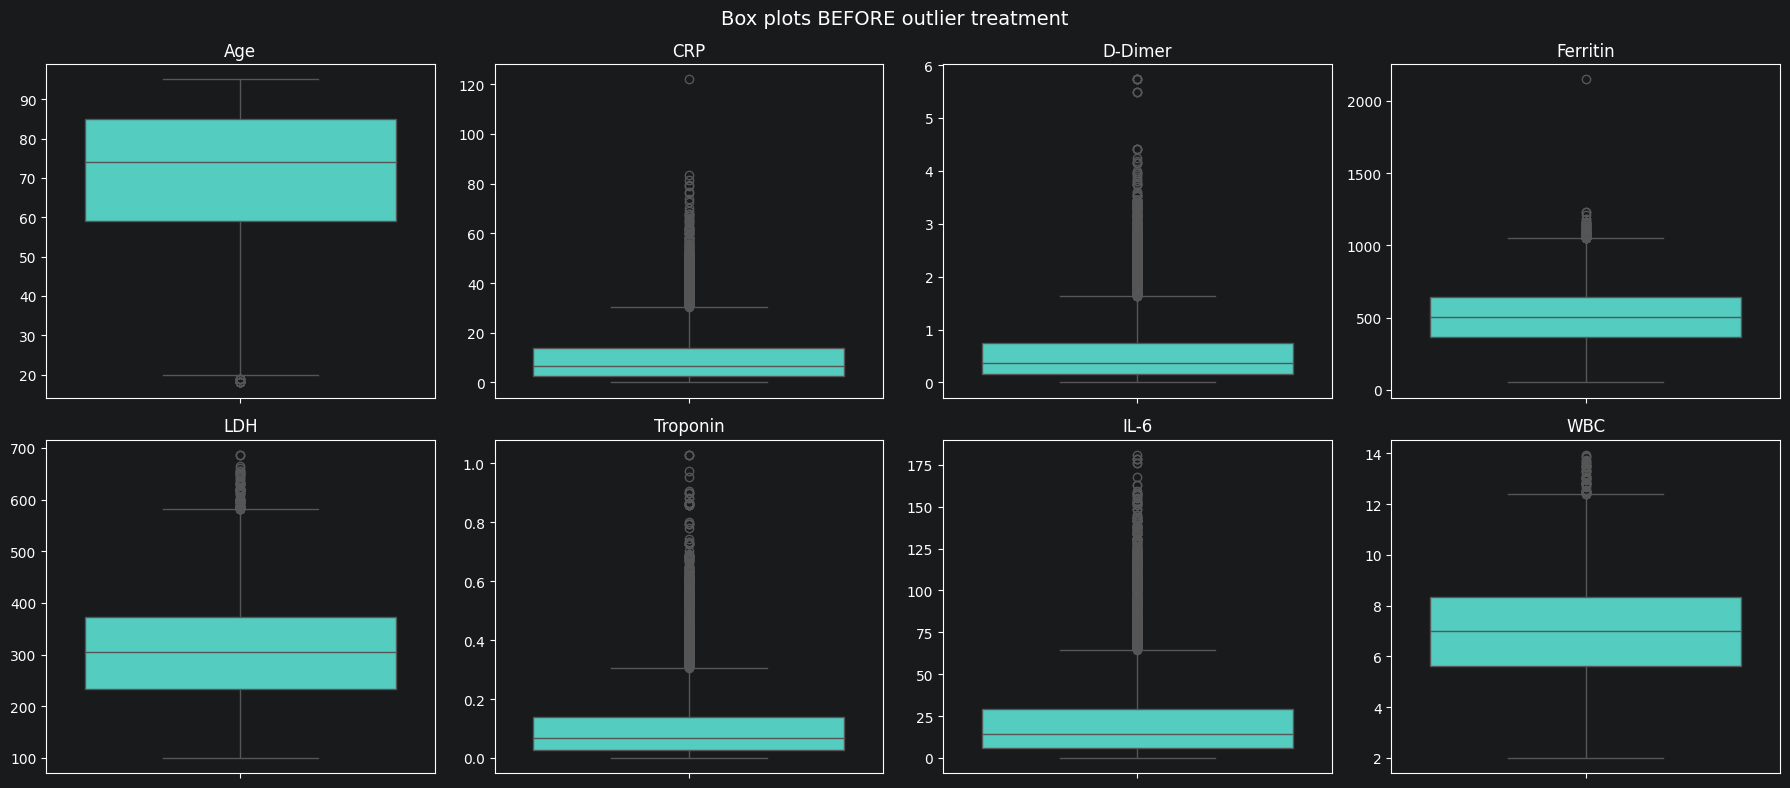

In [169]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_features):
    sns.boxplot(y=df[col], ax=ax, color="turquoise")
    ax.set_title(col)
    ax.set_ylabel("")
plt.suptitle("Box plots BEFORE outlier treatment", fontsize=14)
plt.tight_layout()
plt.show()

### Handle outliers
** Decision: We do not delete rows:

- The
IQR
rule
flags
5 - 8 % of
rows
for the skewed lab markers.That is a lot, and it mostly reflects right-skewed distributions rather than errors.In COVID patients, extreme CRP, IL-6, D-Dimer and Troponin values are often the ** signal ** of severe illness.
- Instead, ** winsorize **: cap
each
numeric
feature
at
its
1
st and 99
th
percentile.This
limits
the
pull
of
the
most
extreme
values
but
keeps
every
patient.
- The
sensitivity
check in Step
4.7
compares
this
against
doing
nothing, log
transforms, and IQR
capping.

In [170]:
df_before_capping = df.copy()  # kept for the sensitivity check later

caps = {}
for col in num_features:
    lo, hi = df[col].quantile([0.01, 0.99])
    caps[col] = (lo, hi)
    df[col] = df[col].clip(lo, hi)

pd.DataFrame(caps, index=["lower_cap", "upper_cap"]).T.round(3)

,lower_cap,upper_cap
Age,31.000,95.000
CRP,0.089,45.447
D-Dimer,0.005,2.816
Ferritin,50.000,1030.639
LDH,100.000,561.132
Troponin,0.001,0.552
IL-6,0.179,116.515
WBC,2.367,11.548
NLR,0.033,17.368


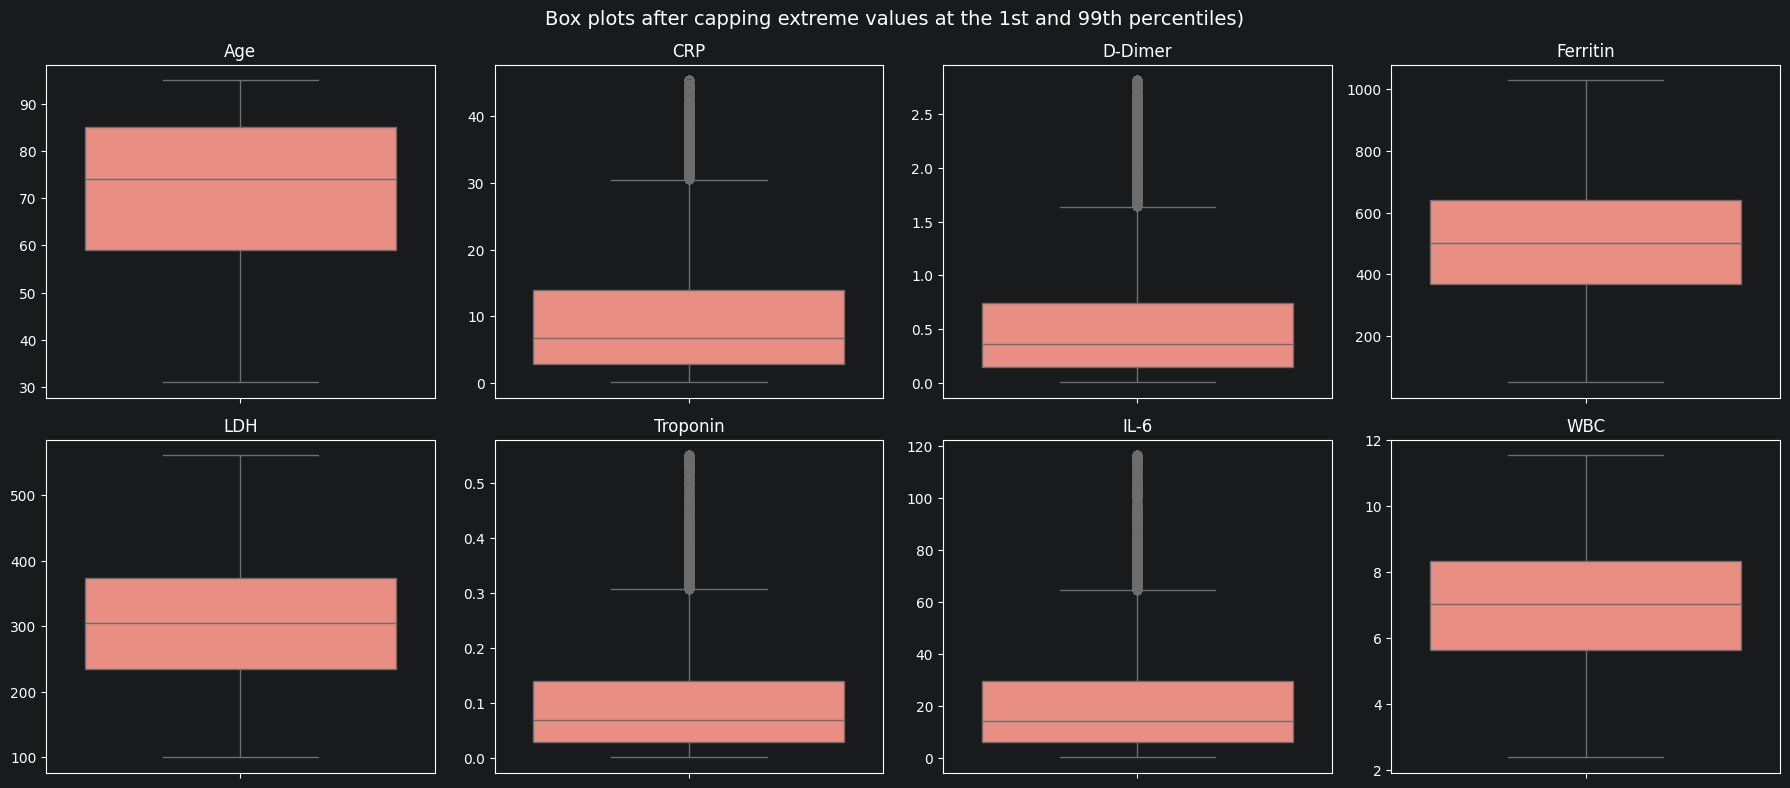

In [171]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_features):
    sns.boxplot(y=df[col], ax=ax, color="salmon")
    ax.set_title(col)
    ax.set_ylabel("")
plt.suptitle("Box plots after capping extreme values at the 1st and 99th percentiles)", fontsize=14)
# Feature distributions after outlier treatment -values below the 1st or above the 99th percentile were capped, no rows removed
plt.tight_layout()
plt.show()

## Step 2: Exploratory Data Analysis & Visualization

In [172]:
df[features + ["Death"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Age,17541.0,71.359,16.493,31.000,59.000,74.000,85.000,95.000
Gender,17541.0,0.499,0.500,0.000,0.000,0.000,1.000,1.000
CRP,17541.0,9.926,9.580,0.089,2.798,6.795,13.888,45.447
D-Dimer,17541.0,0.558,0.586,0.005,0.152,0.365,0.747,2.816
Ferritin,17541.0,506.779,200.997,50.000,367.594,503.396,640.422,1030.639
LDH,17541.0,306.279,102.600,100.000,234.204,304.708,373.018,561.132
Troponin,17541.0,0.102,0.105,0.001,0.028,0.069,0.140,0.552
IL-6,17541.0,21.461,22.480,0.179,5.914,14.318,29.414,116.515
WBC,17541.0,6.995,1.944,2.367,5.630,7.010,8.334,11.548
NLR,17541.0,3.619,3.786,0.033,0.941,2.259,4.844,17.368


### 2.1 Feature distributions

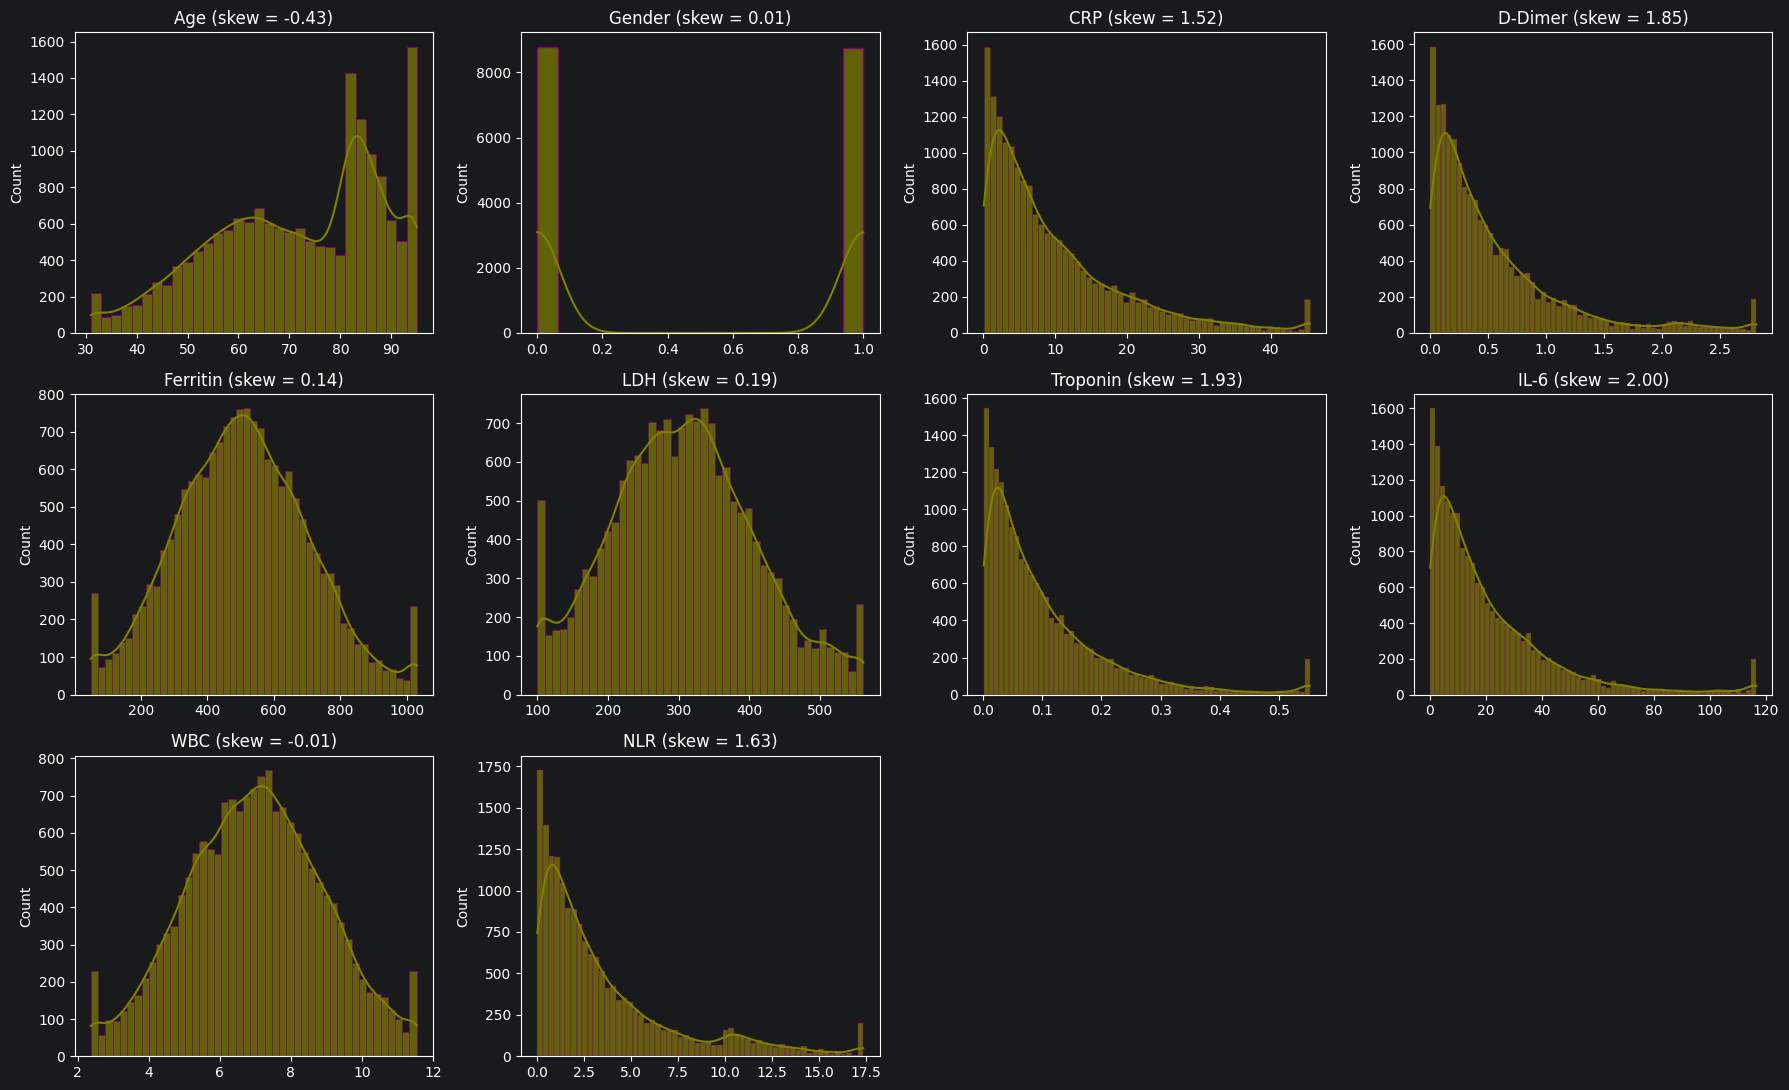

In [173]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col], kde=True, ax=ax, color="olive", edgecolor="purple", alpha=0.7)
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
    ax.set_xlabel("")
for ax in axes.ravel()[len(features):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 2.2 Features vs. Outcomes

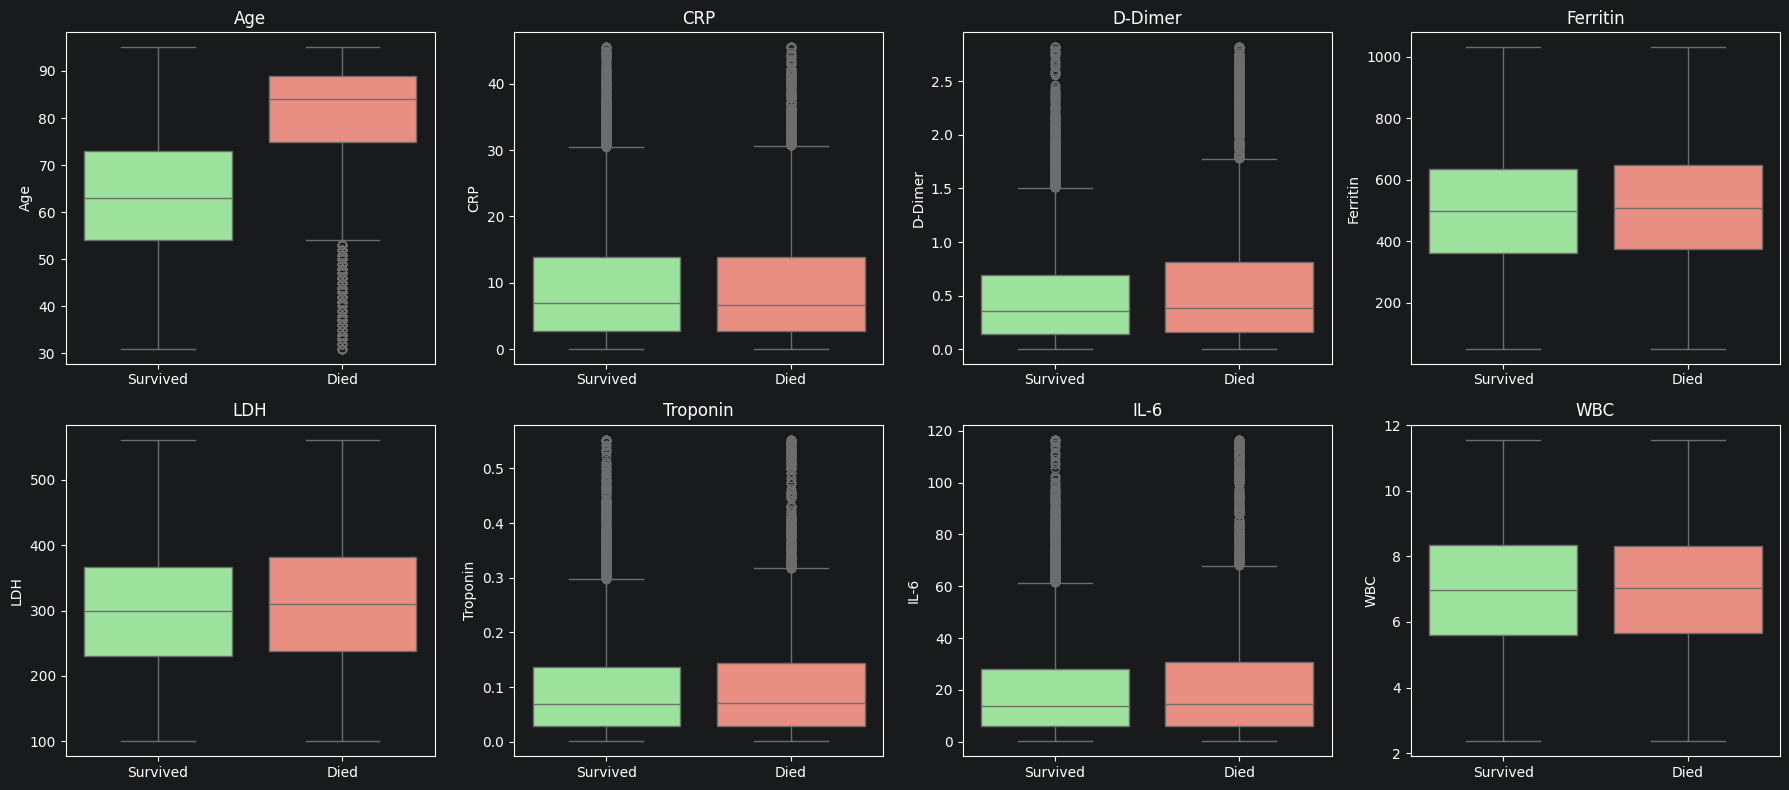

In [174]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_features):
    sns.boxplot(data=df, x="Death", y=col, ax=ax, palette=["lightgreen", "salmon"])
    ax.set_xticklabels(["Survived", "Died"])
    ax.set_xlabel("")
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 2.3 Correlation Heatmap

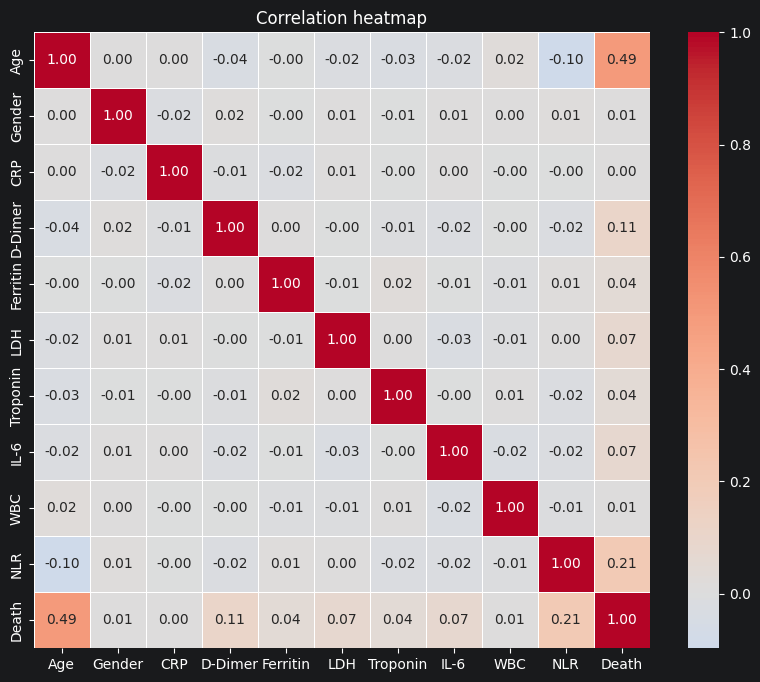

Correlation with Death:
Age         0.494
NLR         0.208
D-Dimer     0.106
LDH         0.071
IL-6        0.070
Ferritin    0.043
Troponin    0.041
WBC         0.008
Gender      0.005
CRP         0.001
Name: Death, dtype: float64


In [175]:
plt.figure(figsize=(10, 8))
corr = df[features + ["Death"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation heatmap")
plt.show()

print("Correlation with Death:")
print(corr["Death"].drop("Death").sort_values(ascending=False).round(3))

### 2.4 Class Balance of Death

Death
0    8770
1    8771
Name: count, dtype: int64
Death
0    50.0 %
1    50.0 %
Name: count, dtype: object


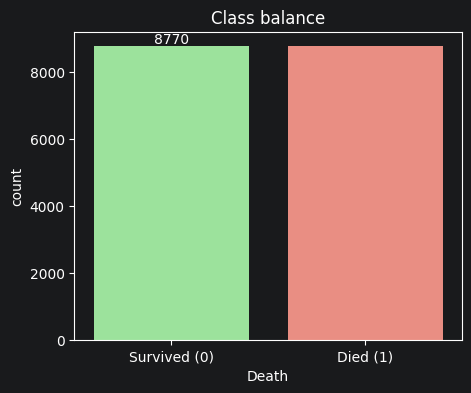

In [176]:
counts = df["Death"].value_counts().sort_index()
print(counts)
print((counts / len(df) * 100).round(1).astype(str) + " %")

plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="Death", palette=["lightgreen", "salmon"])
ax.set_xticklabels(["Survived (0)", "Died (1)"])
ax.bar_label(ax.containers[0])
plt.title("Class balance")
plt.show()

## Step 3: Build the Logistic Regression Model

In [177]:
X = df[features]
y = df["Death"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)

# Fit the scaler on the TRAIN set only, then apply it to both sets
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_s, y_train)

y_pred = model.predict(X_test_s)
y_prob = model.predict_proba(X_test_s)[:, 1]

Train: (14032, 10)  Test: (3509, 10)


## Step 4: Model Evaluation

### 4.1 Confusion Matrix

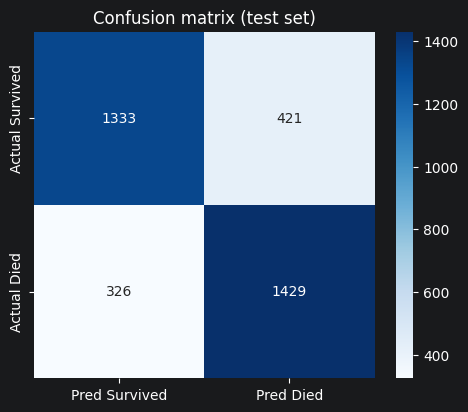

True negatives : 1333
False positives: 421  (predicted death, patient survived)
False negatives: 326  (predicted survival, patient died)  <- the costly error
True positives : 1429


In [178]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Survived", "Pred Died"],
            yticklabels=["Actual Survived", "Actual Died"])
plt.title("Confusion matrix (test set)")
plt.ylabel("")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True negatives : {tn}")
print(f"False positives: {fp}  (predicted death, patient survived)")
print(f"False negatives: {fn}  (predicted survival, patient died)  <- the costly error")
print(f"True positives : {tp}")

In [179]:
metrics = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall":    recall_score(y_test, y_pred),
    "F1-score":  f1_score(y_test, y_pred),
    "ROC-AUC":   roc_auc_score(y_test, y_prob),
}
pd.Series(metrics).round(4).to_frame("Test score")

,Test score
Accuracy,0.7871
Precision,0.7724
Recall,0.8142
F1-score,0.7928
ROC-AUC,0.8511


In [180]:
print(classification_report(y_test, y_pred, target_names=["Survived", "Died"]))

              precision    recall  f1-score   support

    Survived       0.80      0.76      0.78      1754
        Died       0.77      0.81      0.79      1755

    accuracy                           0.79      3509
   macro avg       0.79      0.79      0.79      3509
weighted avg       0.79      0.79      0.79      3509



### 4.3 ROC curve

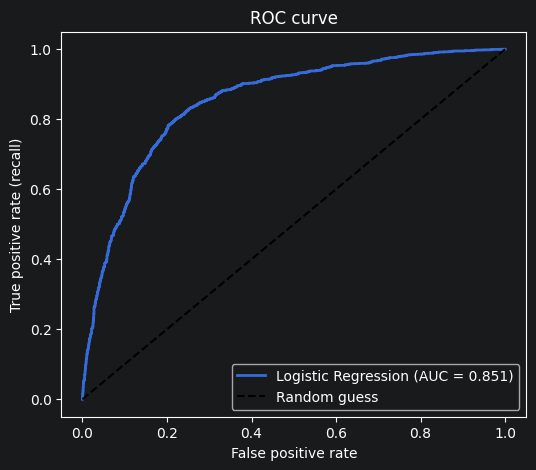

In [181]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, lw=2, label=f"Logistic Regression (AUC = {metrics['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curve")
plt.legend()
plt.show()

### 4.4 Feature importance (coefficients)
Features were standardized, so coefficients are directly comparable: a positive coefficient raises the log-odds of death, a negative one lowers it. The odds ratio is the change in odds of death for a **+1 standard deviation** increase in that feature.

,feature,coefficient,odds_ratio
0,Age,1.573,4.819
9,NLR,0.829,2.292
3,D-Dimer,0.421,1.523
7,IL-6,0.288,1.334
5,LDH,0.260,1.297
6,Troponin,0.183,1.201
4,Ferritin,0.142,1.153
2,CRP,0.005,1.005
1,Gender,0.002,1.002
8,WBC,0.001,1.001


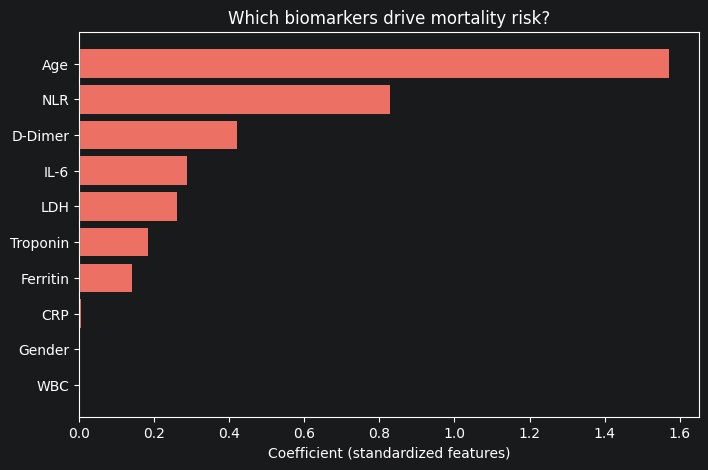

In [182]:
coef_df = pd.DataFrame({
    "feature": features,
    "coefficient": model.coef_[0],
    "odds_ratio": np.exp(model.coef_[0]),
}).sort_values("coefficient", ascending=False)
display(coef_df.round(3))

plt.figure(figsize=(8, 5))
colors = ["#ec7063" if c > 0 else "#5dade2" for c in coef_df["coefficient"]]
plt.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.gca().invert_yaxis()
plt.xlabel("Coefficient (standardized features)")
plt.title("Which biomarkers drive mortality risk?")
plt.show()

### 4.5 Threshold and recall
The default cutoff is 0.5. If catching deaths matters most, you can lower the threshold to trade some precision for higher recall.

In [183]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    p = (y_prob >= t).astype(int)
    rows.append([t, accuracy_score(y_test, p), precision_score(y_test, p),
                 recall_score(y_test, p), f1_score(y_test, p)])
pd.DataFrame(rows, columns=["threshold", "accuracy", "precision", "recall", "f1"]).round(3)

,threshold,accuracy,precision,recall,f1
0,0.3,0.742,0.680,0.912,0.779
1,0.4,0.775,0.728,0.879,0.796
2,0.5,0.787,0.772,0.814,0.793
3,0.6,0.772,0.813,0.707,0.756


### 4.6 Overfitting check
Train and test scores should be close.

In [184]:
print("Train accuracy:", round(accuracy_score(y_train, model.predict(X_train_s)), 4))
print("Test accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Train ROC-AUC :", round(roc_auc_score(y_train, model.predict_proba(X_train_s)[:, 1]), 4))
print("Test ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

Train accuracy: 0.7908
Test accuracy : 0.7871
Train ROC-AUC : 0.8521
Test ROC-AUC  : 0.8511


### 4.7 Sensitivity check: does the outlier decision matter?
Same pipeline, different outlier treatments, same split.

In [185]:
def evaluate(data, label):
    Xa, ya = data[features], data["Death"]
    Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=0.2, stratify=ya, random_state= 42)
    sc = StandardScaler().fit(Xtr)
    m = LogisticRegression(max_iter=1000).fit(sc.transform(Xtr), ytr)
    p = m.predict(sc.transform(Xte))
    pr = m.predict_proba(sc.transform(Xte))[:, 1]
    return [label, accuracy_score(yte, p), recall_score(yte, p), f1_score(yte, p), roc_auc_score(yte, pr)]

skewed = ["CRP", "D-Dimer", "Troponin", "IL-6", "NLR"]
results = []

results.append(evaluate(df_before_capping, "No outlier treatment"))
results.append(evaluate(df, "Winsorize 1st-99th pct (used)"))

d = df_before_capping.copy()
for col in num_features:
    q1, q3 = d[col].quantile([0.25, 0.75]); iqr = q3 - q1
    d[col] = d[col].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
results.append(evaluate(d, "Cap at IQR fences"))

d = df_before_capping.copy()
for col in skewed:
    d[col] = np.log1p(d[col])
results.append(evaluate(d, "log1p on skewed labs"))

pd.DataFrame(results, columns=["method", "accuracy", "recall", "f1", "roc_auc"]).round(4)

,method,accuracy,recall,f1,roc_auc
0,No outlier treatment,0.7888,0.8160,0.7945,0.8519
1,Winsorize 1st-99th pct (used),0.7871,0.8142,0.7928,0.8511
2,Cap at IQR fences,0.7751,0.8034,0.7814,0.8371
3,log1p on skewed labs,0.7652,0.7892,0.7707,0.8300


## Step 5: Save & Deploy the Model

In [186]:
bundle = {
    "model": model,
    "scaler": scaler,
    "features": features,   # column order used in training
    "caps": caps,           # Capping limits for each numeric feature (1st and 99th percentiles)
}
joblib.dump(bundle, "covid_mortality_model.joblib")
print("Saved covid_mortality_model.joblib")

Saved covid_mortality_model.joblib


In [187]:
loaded = joblib.load("covid_mortality_model.joblib")


def predict_patient(patient: dict, threshold: float = 0.5, bundle=loaded):
    """Return the probability of death and a priority label for one patient.
    patient: dict with Age, Gender ('Male'/'Female'), CRP, D-Dimer, Ferritin,
             LDH, Troponin, IL-6, WBC, NLR
    """
    row = pd.DataFrame([patient])
    row["Gender"] = row["Gender"].map({"Male": 1, "Female": 0})
    for col, (lo, hi) in bundle["caps"].items():
        row[col] = row[col].clip(lo, hi)
    row = row[bundle["features"]]
    prob = bundle["model"].predict_proba(bundle["scaler"].transform(row))[0, 1]
    label = "HIGH RISK - prioritize treatment" if prob >= threshold else "Lower risk"
    return prob, label


high_risk_patient = {"Age": 85, "Gender": "Male", "CRP": 25.0, "D-Dimer": 1.5,
                     "Ferritin": 800, "LDH": 450, "Troponin": 0.30,
                     "IL-6": 60.0, "WBC": 9.0, "NLR": 8.0}
low_risk_patient = {"Age": 35, "Gender": "Female", "CRP": 2.0, "D-Dimer": 0.1,
                    "Ferritin": 300, "LDH": 250, "Troponin": 0.02,
                    "IL-6": 5.0, "WBC": 7.0, "NLR": 1.5}

for name, p in [("High-risk example", high_risk_patient), ("Low-risk example", low_risk_patient)]:
    prob, label = predict_patient(p)
    print(f"{name}: P(death) = {prob:.1%} -> {label}")

High-risk example: P(death) = 98.6% -> HIGH RISK - prioritize treatment
Low-risk example: P(death) = 0.7% -> Lower risk


## Challenge Section: Improving Recall and Trying Other Models
The brief asks three questions: how to raise recall, whether another model does better, and whether GridSearchCV helps. All models below use the **same train/test rows** as the baseline, so the comparison is fair.

In [188]:
results = []


def log_result(name, y_true, y_pred, y_prob):
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_prob),
    })


log_result("Baseline logistic regression", y_test, y_pred, y_prob)

### Challenge 1: How can we improve recall?
**Option A: lower the decision threshold.** Already shown in 4.5: threshold 0.3 gives recall about 0.91 but precision drops to about 0.68. It catches more deaths but raises many false alarms.

**Option B: class weights.** Penalize missed deaths more during training.

In [189]:
lr_cw = LogisticRegression(max_iter=1000, class_weight={0: 1, 1: 1.5}, random_state= 42)
lr_cw.fit(X_train_s, y_train)
log_result("Logistic regression, death class weight 1.5", y_test,
           lr_cw.predict(X_test_s), lr_cw.predict_proba(X_test_s)[:, 1])
pd.DataFrame(results).round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,Baseline logistic regression,0.7871,0.7724,0.8142,0.7928,0.8511
1,"Logistic regression, death class weight 1.5",0.7734,0.7281,0.8729,0.7940,0.8506


**Option C: fix what the model cannot see.** Logistic regression assumes each feature changes the log-odds in a *straight line*. Let's check whether that is true for `Age`, the strongest feature.

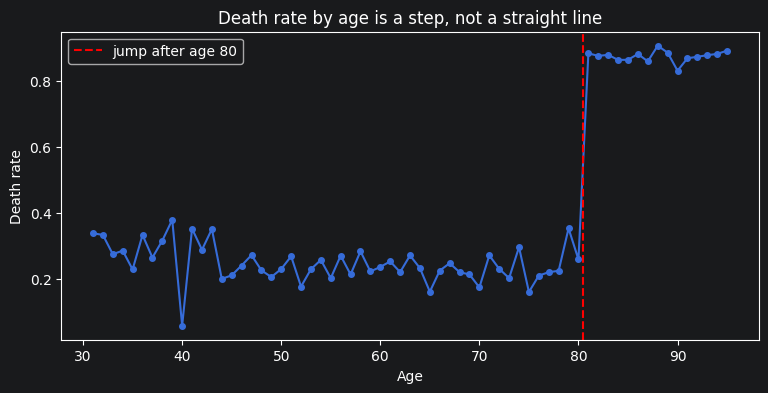

Death rate, ages 31-80: 0.24
Death rate, ages 81+  : 0.878


In [190]:
age_rate = df.groupby("Age")["Death"].mean()

plt.figure(figsize=(9, 4))
plt.plot(age_rate.index, age_rate.values, marker="o", ms=4)
plt.axvline(80.5, color="red", ls="--", label="jump after age 80")
plt.xlabel("Age")
plt.ylabel("Death rate")
plt.title("Death rate by age is a step, not a straight line")
plt.legend()
plt.show()

print("Death rate, ages 31-80:", round(df.loc[df["Age"] <= 80, "Death"].mean(), 3))
print("Death rate, ages 81+  :", round(df.loc[df["Age"] > 80, "Death"].mean(), 3))

Mortality is roughly flat (about 23%) up to age 80 and then jumps to about 88% from age 81. A straight-line effect cannot represent that step, so the model underfits. Adding a simple **"age over 80" flag** lets logistic regression capture it. This is *feature engineering* and the model stays a logistic regression.

In [191]:
df["Age_over_80"] = (df["Age"] > 80).astype(int)
features_fe = features + ["Age_over_80"]

Xtr_fe = df.loc[X_train.index, features_fe]
Xte_fe = df.loc[X_test.index, features_fe]

scaler_fe = StandardScaler()
Xtr_fe_s = scaler_fe.fit_transform(Xtr_fe)
Xte_fe_s = scaler_fe.transform(Xte_fe)

lr_fe = LogisticRegression(max_iter=1000, random_state= 42).fit(Xtr_fe_s, y_train)
log_result("Logistic regression + Age_over_80 flag", y_test,
           lr_fe.predict(Xte_fe_s), lr_fe.predict_proba(Xte_fe_s)[:, 1])
pd.DataFrame(results).round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,Baseline logistic regression,0.7871,0.7724,0.8142,0.7928,0.8511
1,"Logistic regression, death class weight 1.5",0.7734,0.7281,0.8729,0.7940,0.8506
2,Logistic regression + Age_over_80 flag,0.8512,0.8553,0.8456,0.8504,0.9067


### Challenge 2: Would a different model perform better?
Tree-based models can learn steps and interactions on their own, with no manual feature engineering and no scaling needed.

In [192]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
log_result("Random Forest", y_test, rf.predict(X_test), rf.predict_proba(X_test)[:, 1])

hgb = HistGradientBoostingClassifier(random_state=42)
hgb.fit(X_train, y_train)
log_result("Gradient Boosting (HistGradientBoosting)", y_test, hgb.predict(X_test), hgb.predict_proba(X_test)[:, 1])

# XGBoost is optional: it is used only if installed (pip install xgboost)
try:
    from xgboost import XGBClassifier

    xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                        random_state=42, eval_metric="logloss")
    xgb.fit(X_train, y_train)
    log_result("XGBoost", y_test, xgb.predict(X_test), xgb.predict_proba(X_test)[:, 1])
except ImportError:
    print("xgboost not installed, skipped")

pd.DataFrame(results).round(4)

xgboost not installed, skipped


,model,accuracy,precision,recall,f1,roc_auc
0,Baseline logistic regression,0.7871,0.7724,0.8142,0.7928,0.8511
1,"Logistic regression, death class weight 1.5",0.7734,0.7281,0.8729,0.7940,0.8506
2,Logistic regression + Age_over_80 flag,0.8512,0.8553,0.8456,0.8504,0.9067
3,Random Forest,0.9188,0.8614,0.9983,0.9248,0.9610
4,Gradient Boosting (HistGradientBoosting),0.9185,0.8645,0.9926,0.9241,0.9457


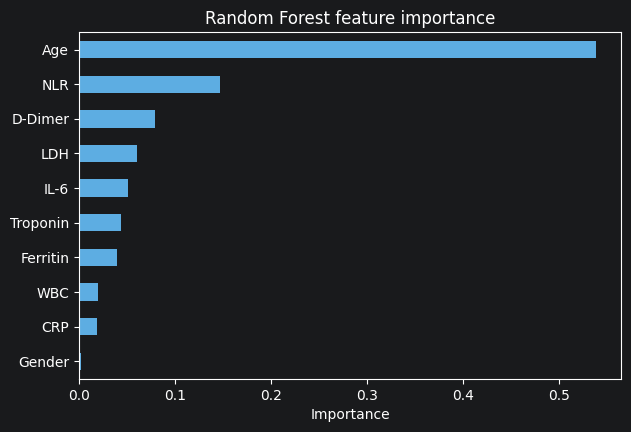

In [193]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
plt.figure(figsize=(7, 4.5))
imp.plot(kind="barh", color="#5dade2")
plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.show()

Challenge 3: Can GridSearchCV optimize hyperparameters?
GridSearchCV tries every combination of settings using cross-validation on the training set only, so the test set stays untouched. For logistic regression we tune C (regularization strength) and class_weight.

We score by F1, not recall alone: a model that predicts "died" for everyone would get a perfect recall of 1.0, so recall by itself would reward a useless model.

In [194]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_lr = GridSearchCV(
    LogisticRegression(max_iter=2000),
    param_grid={"C": [0.001, 0.01, 0.1, 1, 10, 100],
                "class_weight": [None, "balanced", {0: 1, 1: 1.5}]},
    scoring="f1", cv=cv, n_jobs=-1,
)
grid_lr.fit(Xtr_fe_s, y_train)
print("Best logistic regression settings:", grid_lr.best_params_)
print("Best cross-validated F1:", round(grid_lr.best_score_, 4))

best_lr = grid_lr.best_estimator_
log_result("Logistic regression + Age flag, tuned (GridSearchCV)", y_test,
           best_lr.predict(Xte_fe_s), best_lr.predict_proba(Xte_fe_s)[:, 1])

/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: Run

Best logistic regression settings: {'C': 0.01, 'class_weight': {0: 1, 1: 1.5}}
Best cross-validated F1: 0.8632


In [195]:
grid_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    param_grid={"max_depth": [5, None], "min_samples_leaf": [5, 20]},
    scoring="roc_auc", cv=3,
)
grid_rf.fit(X_train, y_train)
print("Best Random Forest settings:", grid_rf.best_params_)
print("Best cross-validated ROC-AUC:", round(grid_rf.best_score_, 4))

best_rf = grid_rf.best_estimator_
log_result("Random Forest, tuned (GridSearchCV)", y_test,
           best_rf.predict(X_test), best_rf.predict_proba(X_test)[:, 1])

Best Random Forest settings: {'max_depth': None, 'min_samples_leaf': 5}
Best cross-validated ROC-AUC: 0.9532


### Final model comparison (test set)

In [198]:
comparison = pd.DataFrame(results).set_index("model").round(4).sort_values("recall", ascending=False)
comparison

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Random Forest,0.9188,0.8614,0.9983,0.9248,0.9610
"Random Forest, tuned (GridSearchCV)",0.9188,0.8614,0.9983,0.9248,0.9605
Gradient Boosting (HistGradientBoosting),0.9185,0.8645,0.9926,0.9241,0.9457
"Logistic regression + Age flag, tuned (GridSearchCV)",0.8584,0.8426,0.8815,0.8616,0.9068
"Logistic regression, death class weight 1.5",0.7734,0.7281,0.8729,0.7940,0.8506
Logistic regression + Age_over_80 flag,0.8512,0.8553,0.8456,0.8504,0.9067
Baseline logistic regression,0.7871,0.7724,0.8142,0.7928,0.8511


**How to read it:** tuning the logistic regression barely helps because its problem is the missing step in `Age`, not its settings. Adding the age flag helps a lot, and tree models do better still because they also find interactions between features. The trade-off is interpretability: logistic regression gives clear odds ratios, while a forest is a black box.

## Summary
- **Cleaning:** gender encoded, impossible ages fixed, one missing target row dropped, remaining gaps filled (median / mode), outliers winsorized rather than deleted.
- **EDA:** balanced classes; skewed lab markers; age is the strongest single correlate of death.
- **Model:** logistic regression on standardized features (80/20 stratified split).
- **Challenge:** mortality jumps from about 23% to about 88% after age 80, which a straight-line model cannot capture. An `Age_over_80` flag, and tree models, improve recall and ROC-AUC clearly. Tuning alone helped little.
- **Deployment:** model, scaler, feature order and caps saved together in one `.joblib` file so new patients are processed exactly like the training data.

*This is a course project on a dataset used for learning. It is not a clinical tool.*